## <span style="color:purple"> Graph Time Series Plots Stacking Each Year </span>

<span style="color:purple"> These graphs will plot series data by day of the year, and then each year will be stacked on top of one another. The purpose of this is to visually inspect the variation in seasonality year-to-year, providing a basis to investigate interannual changes. </span>

### <span style="color:purple"> Plotting function </span>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

position_colours = {0: "tab:blue", 1: "tab:orange", 2: "tab:green"}

def plot_doy(df, borehole, cat, ylim_temp=None, ylim_sal=None):
    # Create a mask to filter the dataframe for the specified borehole and cat
    mask = (df["borehole"] == borehole) & (df["cat"] == cat)
    sub = df[mask].copy()
    
    # Extract day of year and year from the time column
    sub["doy"] = sub["time"].dt.dayofyear + sub["time"].dt.hour / 24 + sub["time"].dt.minute / 1440
    sub["year"] = sub["time"].dt.year

    # Get the unique years in the subset
    years = sorted(sub["year"].unique())
    # Create a colour map for the years
    # tab10 the chosen colour map
    cmap = plt.cm.tab10
    # Create a dictionary mapping each year to a colour
    colours = {year: cmap(i % 10) for i, year in enumerate(years)}

    # sharex=True to share the x-axis between the two subplots
    fig, (axT, axS) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

    for year in years:
        # Filter the subset for the current year
        year_data = sub[sub["year"] == year]
        
        axT.plot(year_data["doy"], year_data["in_situ_temperature_smooth"], lw=0.8, label=str(year), color=colours[year])
        axS.plot(year_data["doy"], year_data["practical_salinity_smooth"], lw=0.8, label=str(year), color=colours[year], linestyle="--")

    axT.set_ylabel("In Situ Temperature (°C)")
    axS.set_ylabel("Practical Salinity (PSS78)")
    axS.set_xlabel("Day of Year")
    axT.set_title(f"{borehole} MicroCAT cat{cat}: Temperature & Salinity")

    axT.legend(ncols=3)
    axS.legend(ncols=3)

    if ylim_temp is not None: axT.set_ylim(*ylim_temp)
    if ylim_sal  is not None: axS.set_ylim(*ylim_sal)

    axT.grid(True); axS.grid(True)
    plt.tight_layout()
    plt.show()

### <span style="color:purple"> Import and apply filtering to DataFrame </span>

<span style="color:purple"> When filtering using a large cutoff period it is often necessary to rely on interpolation
to fill gaps in the data which result from minor discontinuities in data collection. In the below script, we can define the length
of gaps which we are comfortable interpolating across. If we wish not to interpolate, we can set this variable to 0. </span>

In [16]:
from FilterFunctions import apply_lowpass_filter, lowpass_filter

df = pd.read_parquet("../data/proc/03_pressure_handled.parquet")

# Define the cutoff period for filtering in days 
cutoff_period_days = 30  # days
# Define a period of time in days for less than which we are comfortable interpolating for 
# Set this to 0 for no interpolation
interpolate_days = 7 # days
# Apply filtering to the DataFrame
# NOTE: cutoff_period is defined in terms of hours
df_filtered = apply_lowpass_filter(df, cutoff_period=cutoff_period_days*24, sampling_interval=0.5, max_gap_hours=interpolate_days*24)

### <span style="color:purple"> Plot time series graphs of temp and salinity for each borehole/cat by day of the year </span>

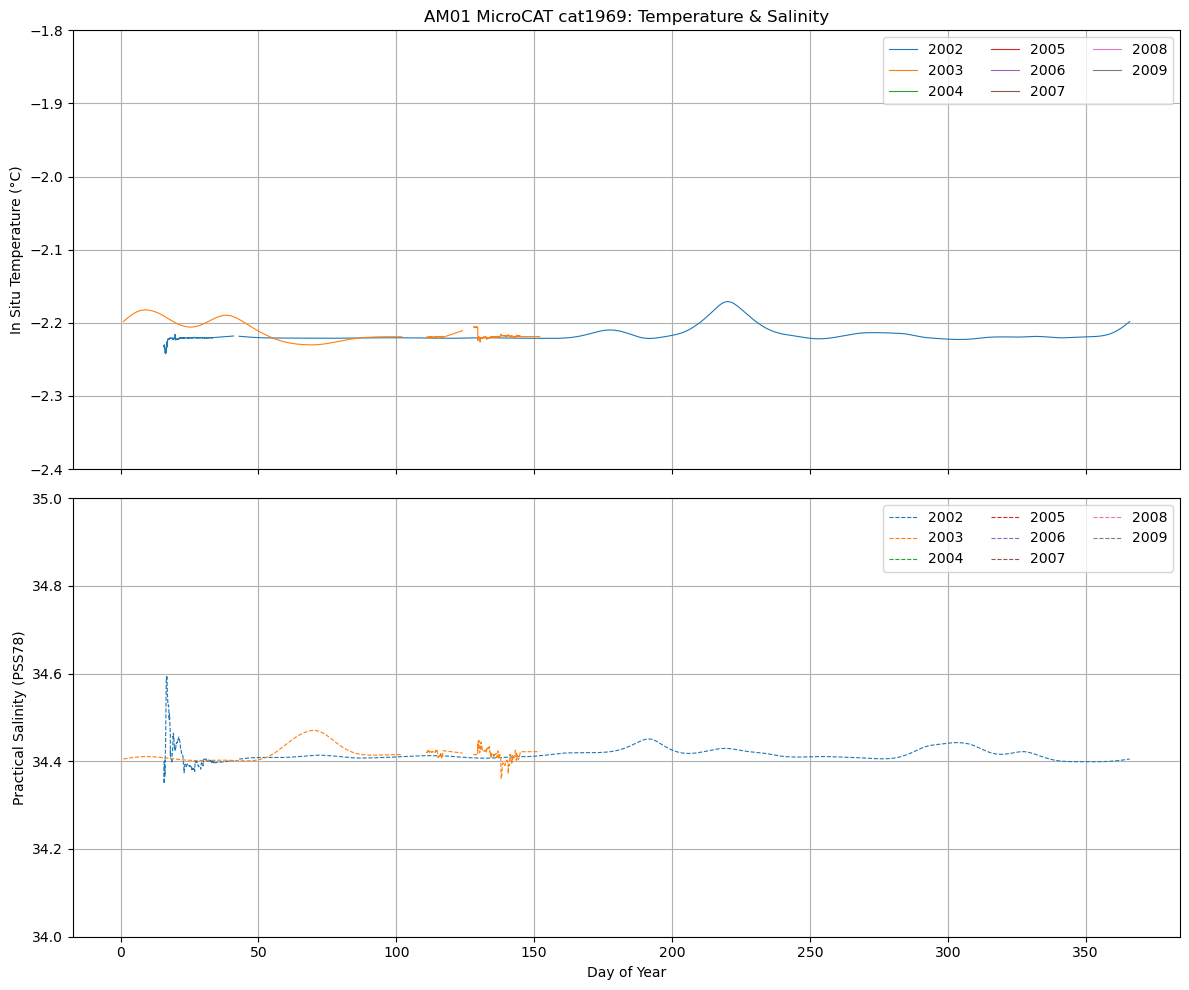

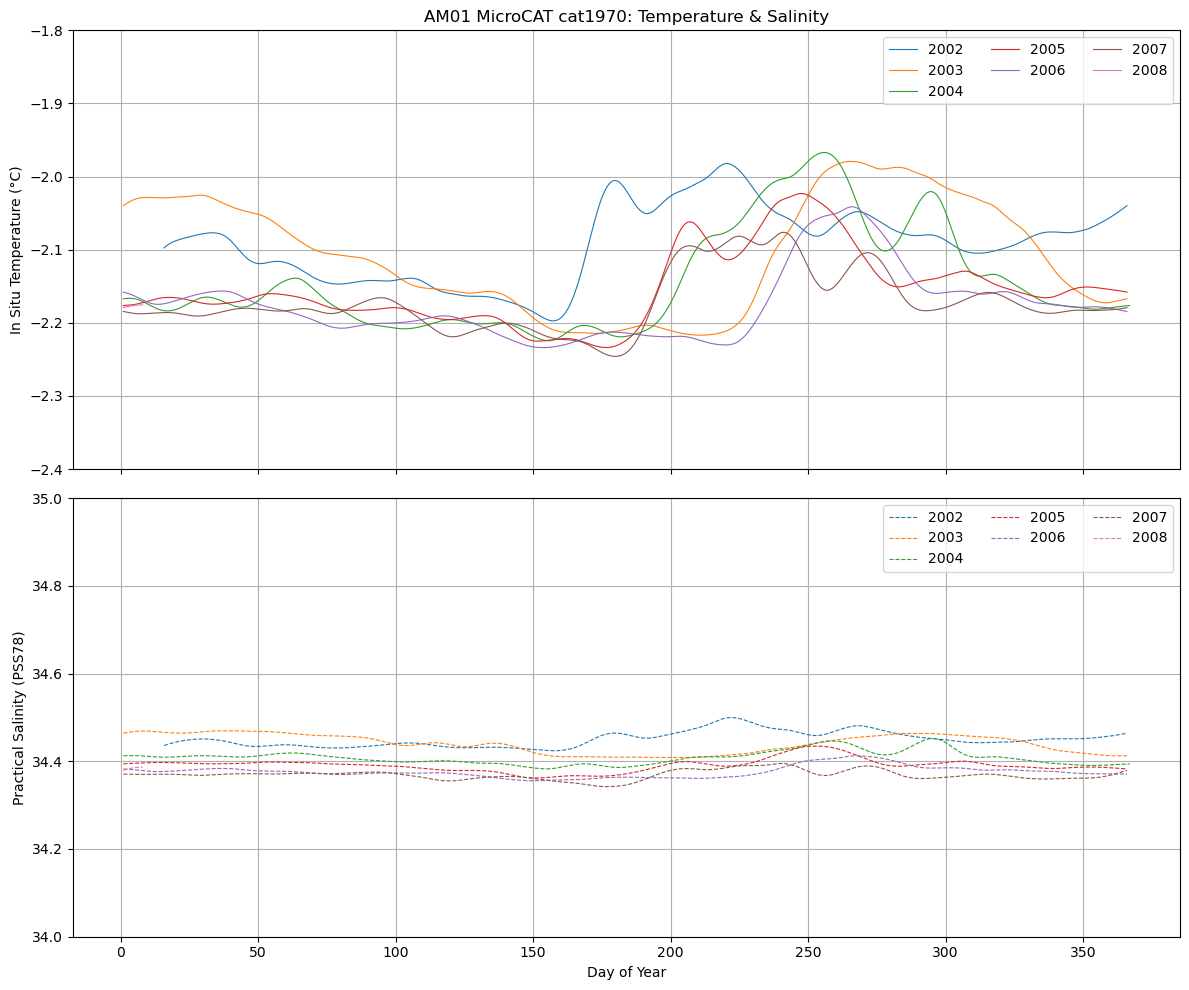

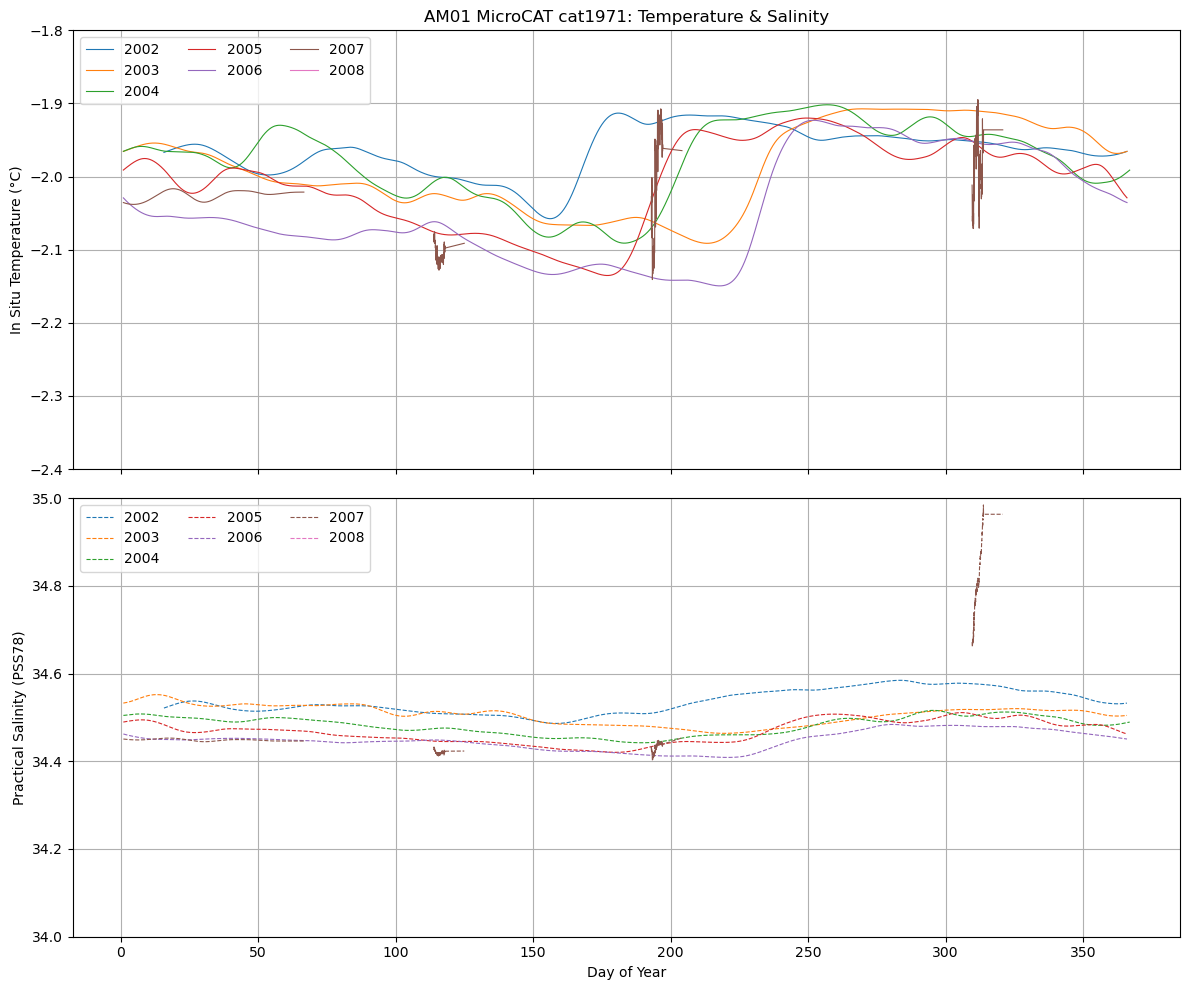

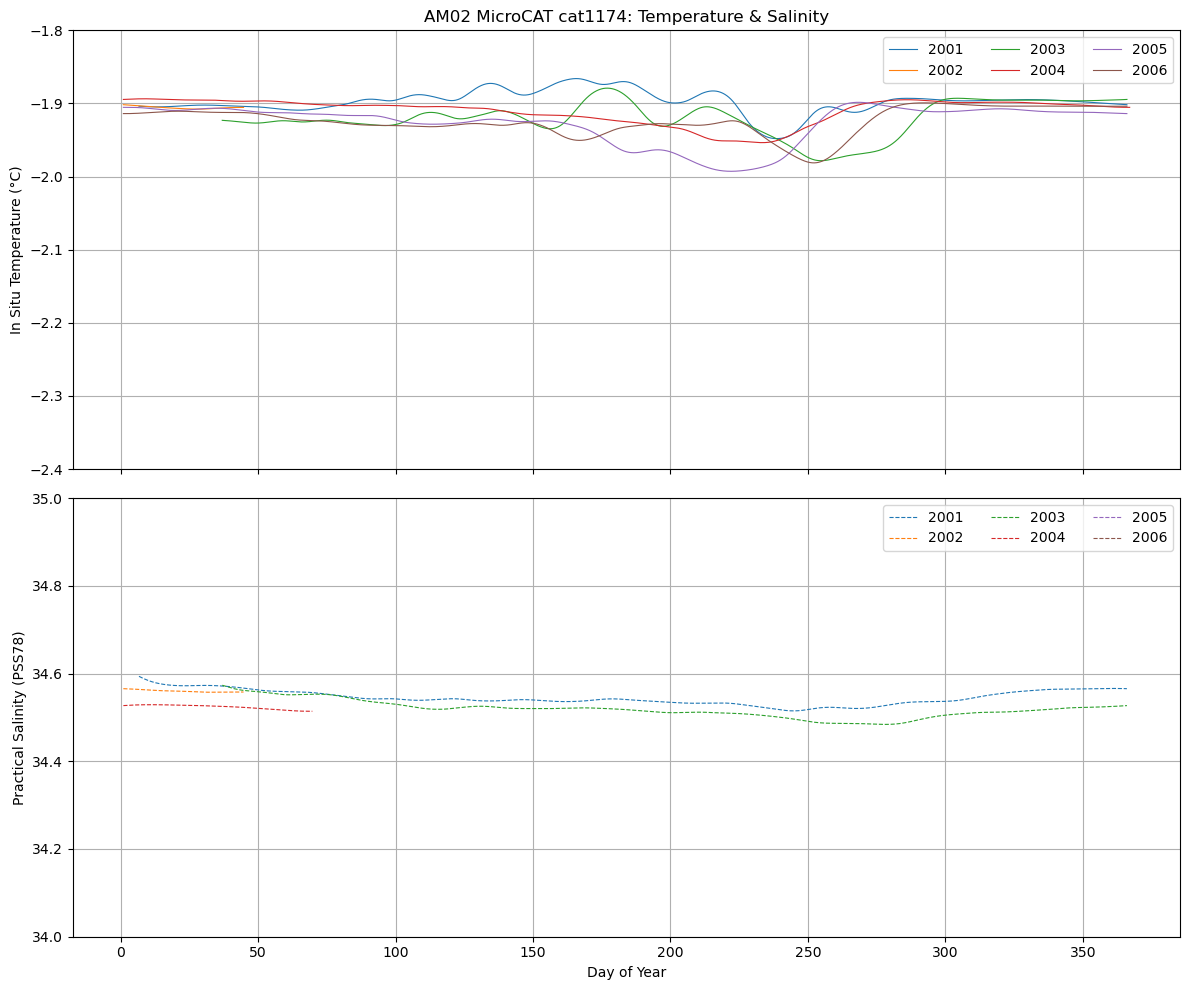

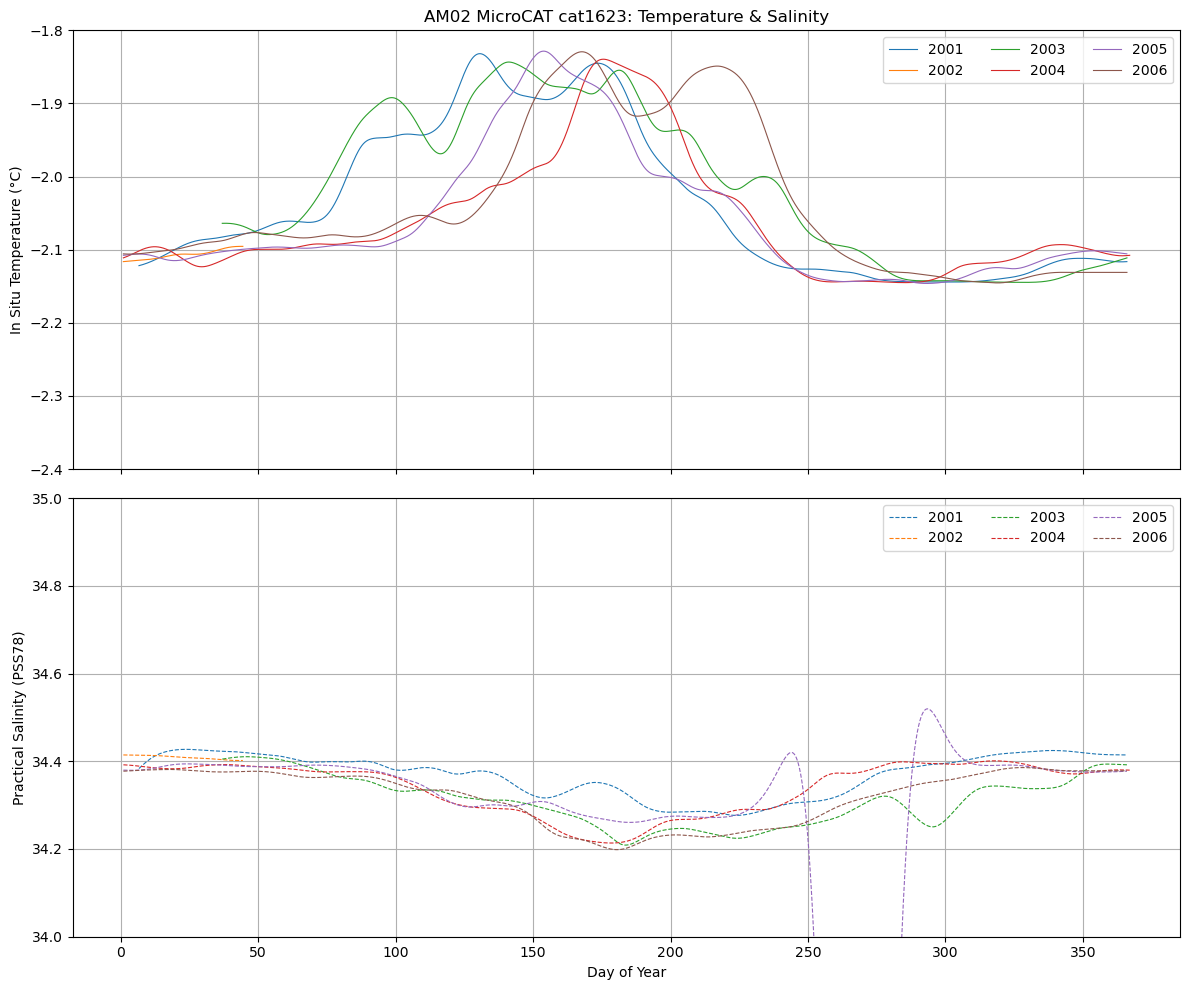

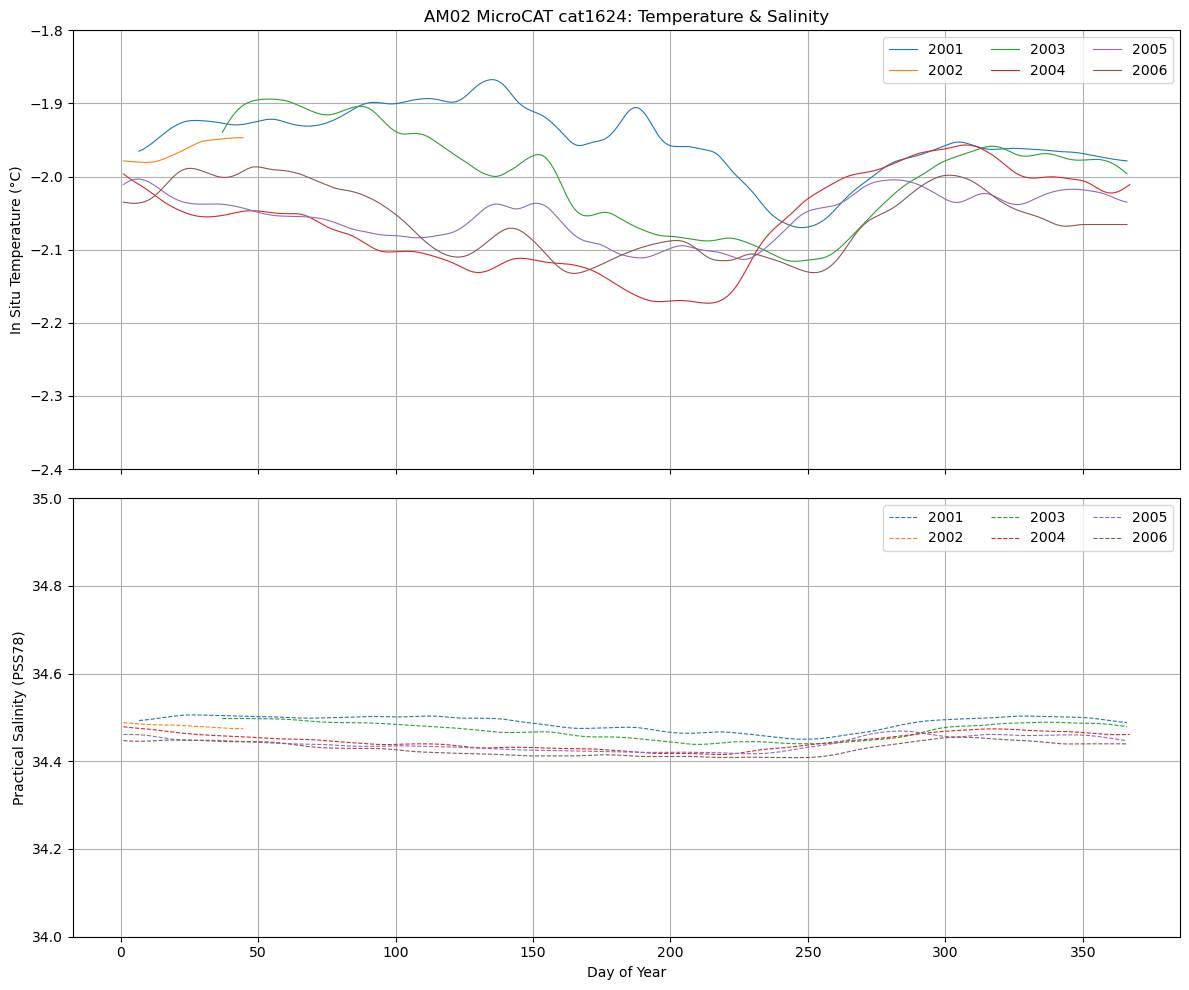

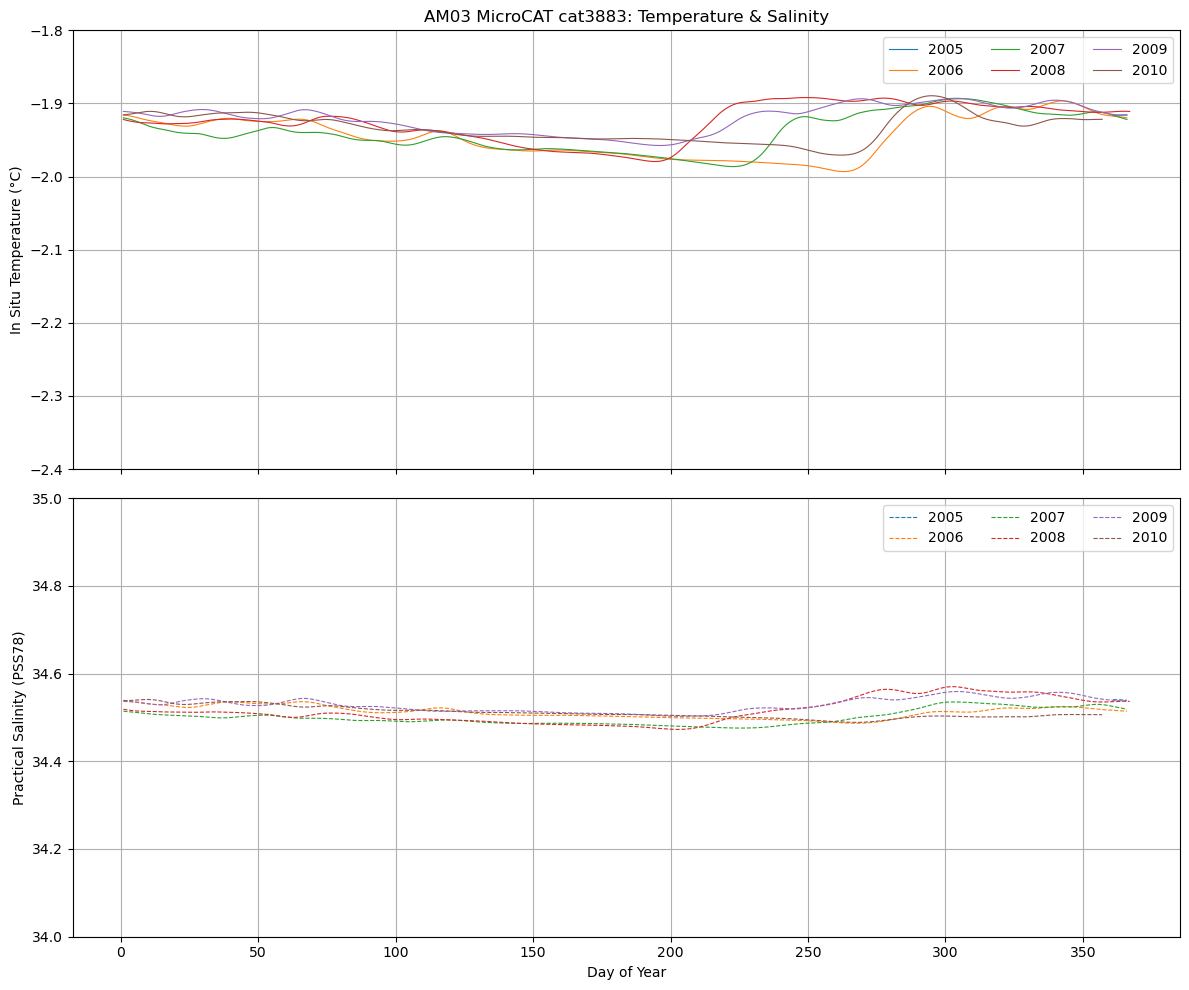

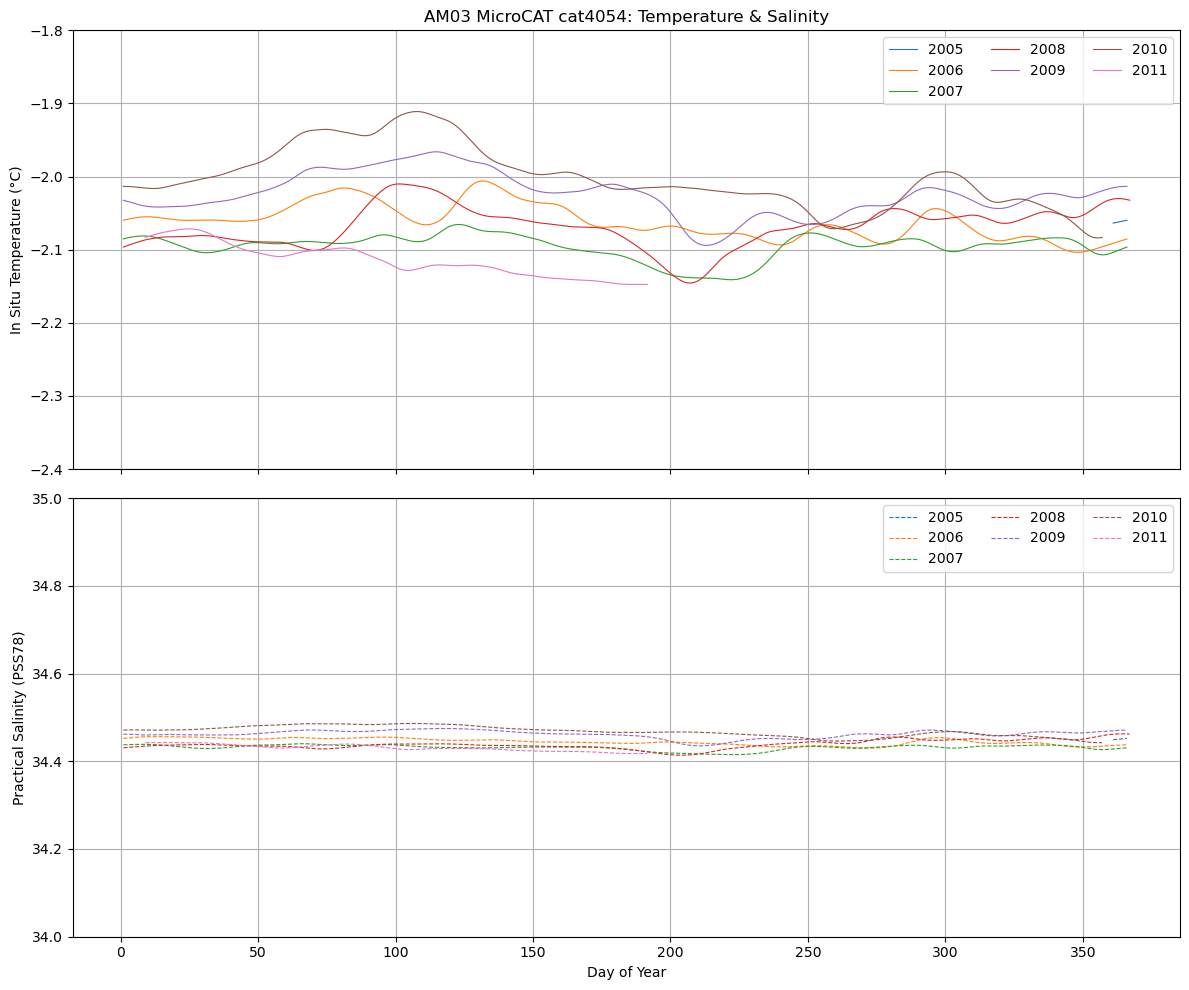

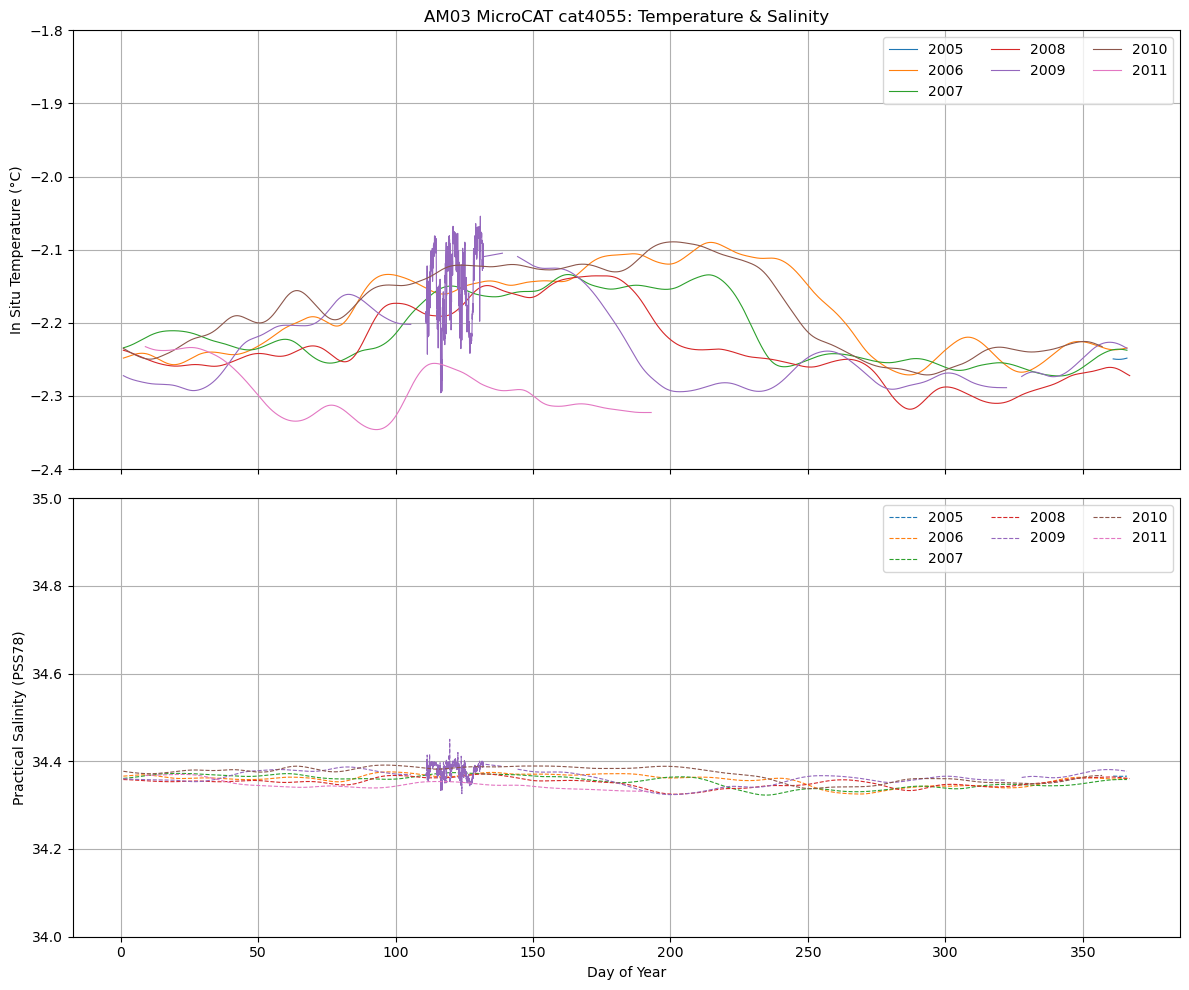

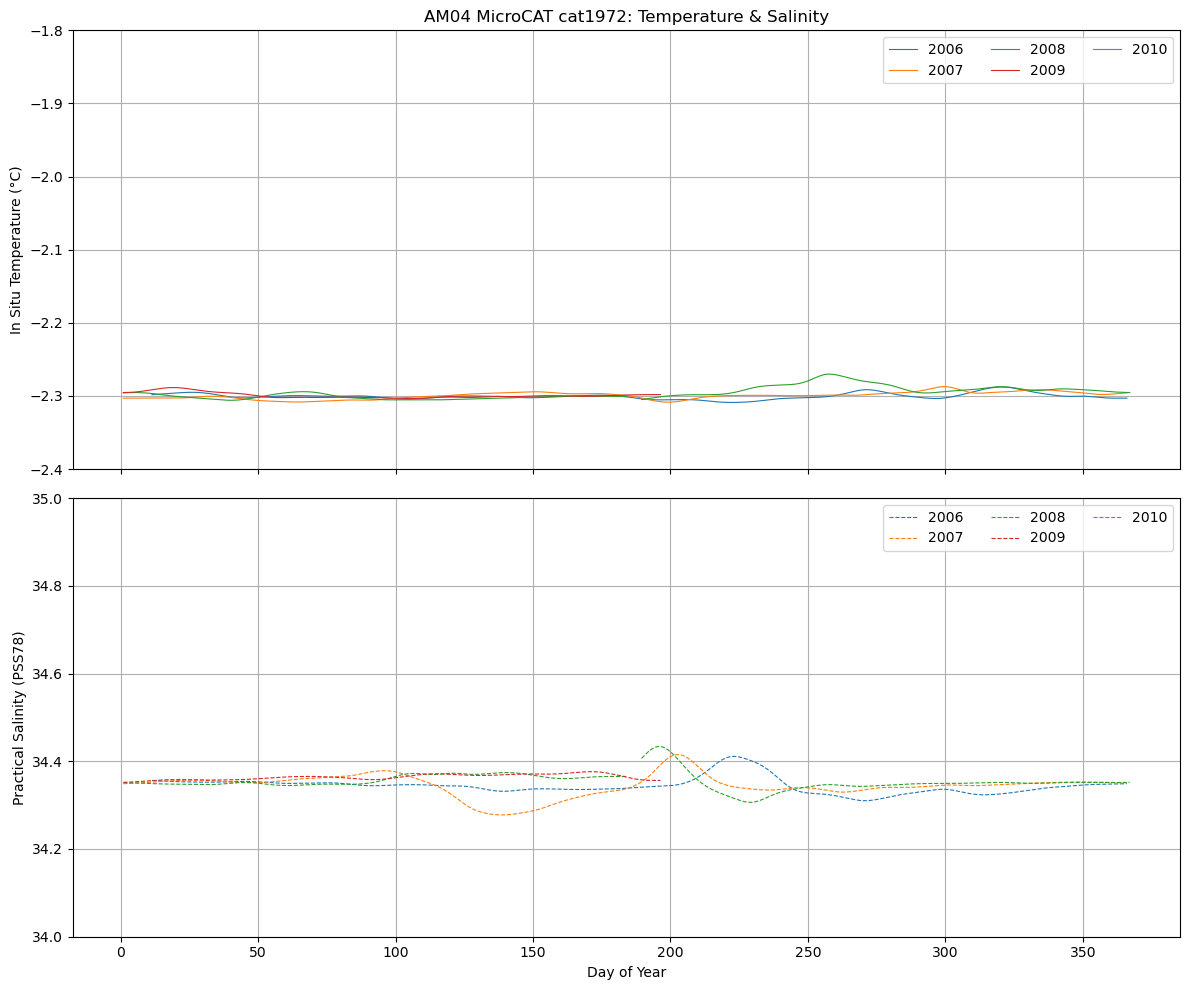

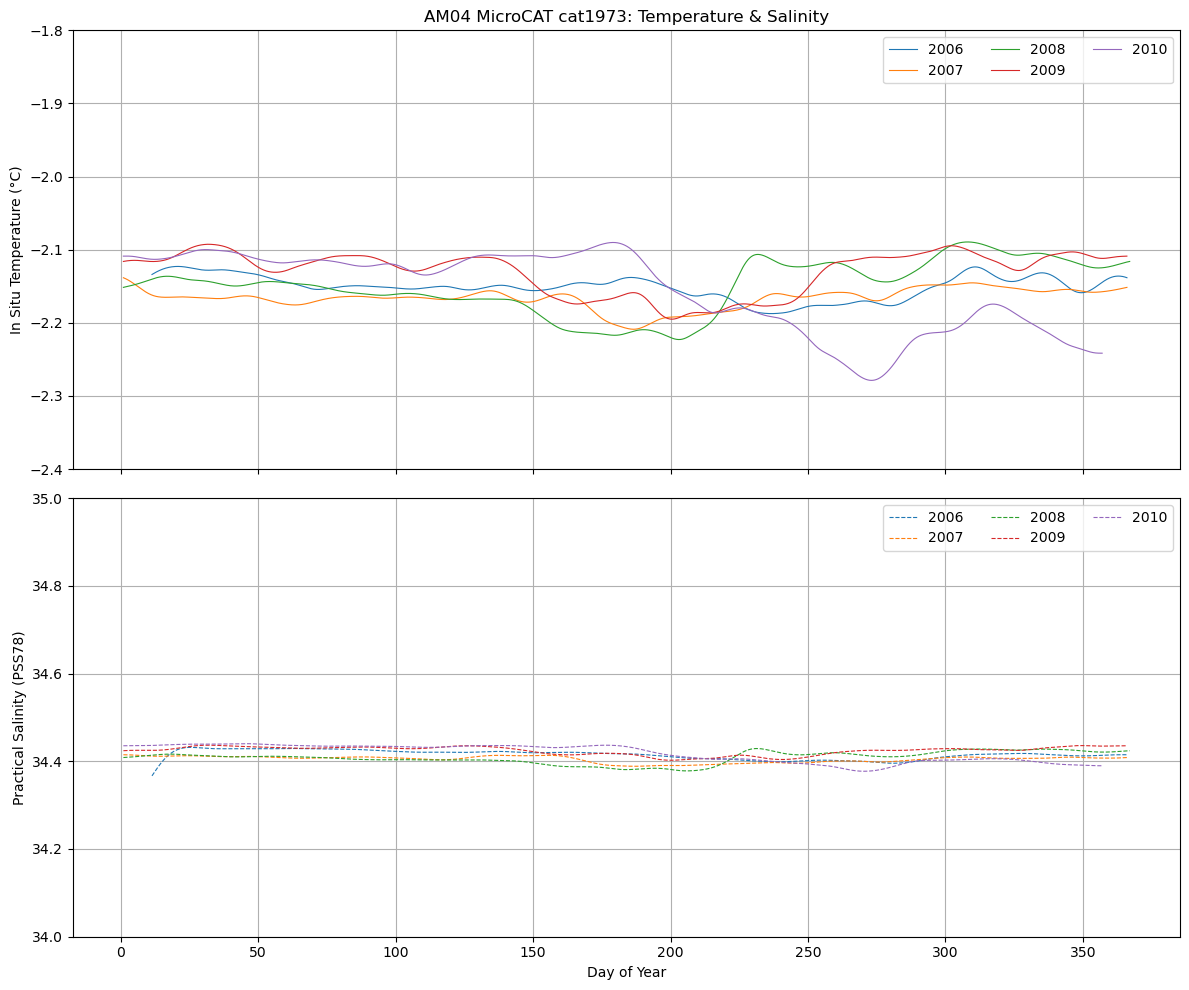

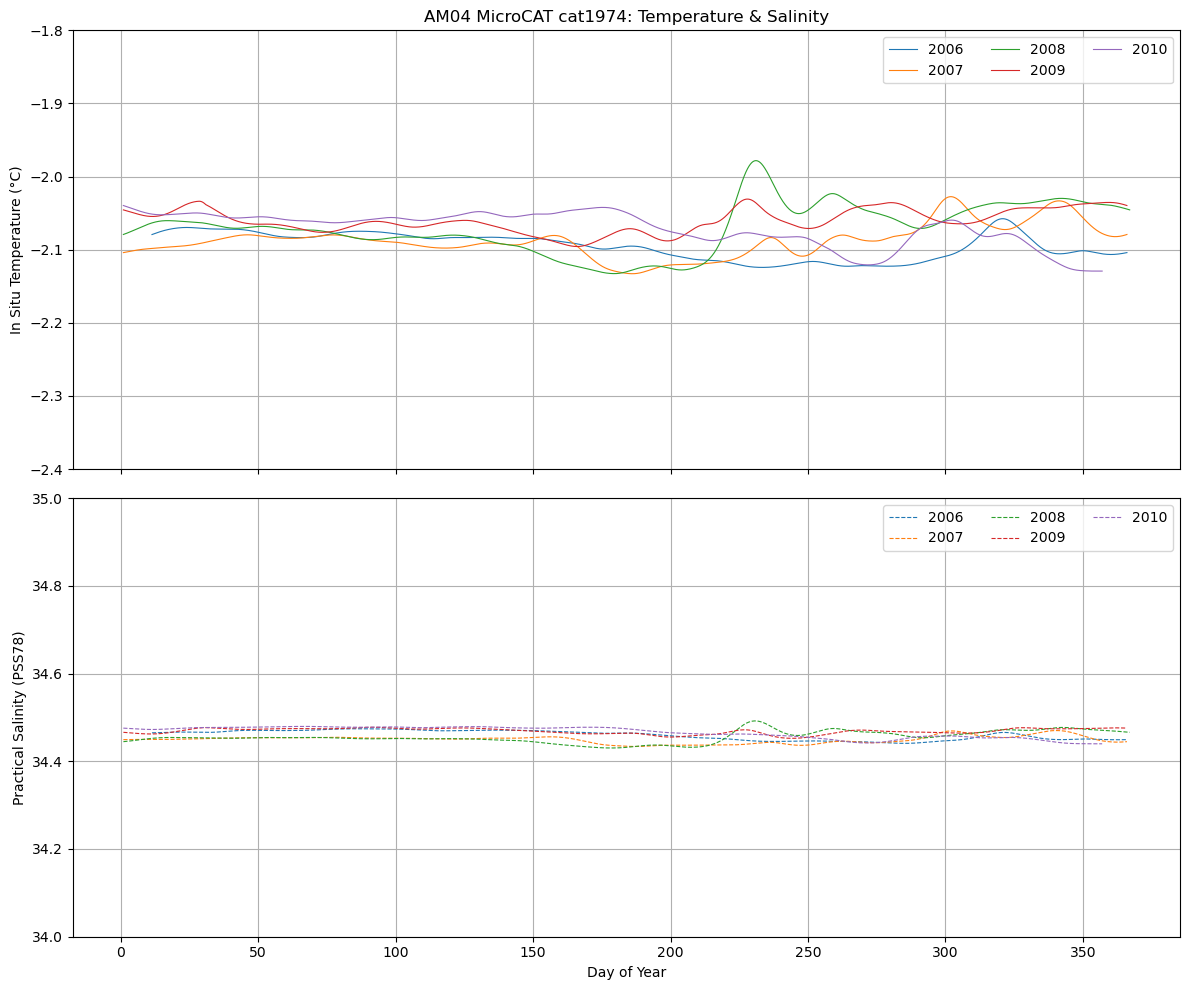

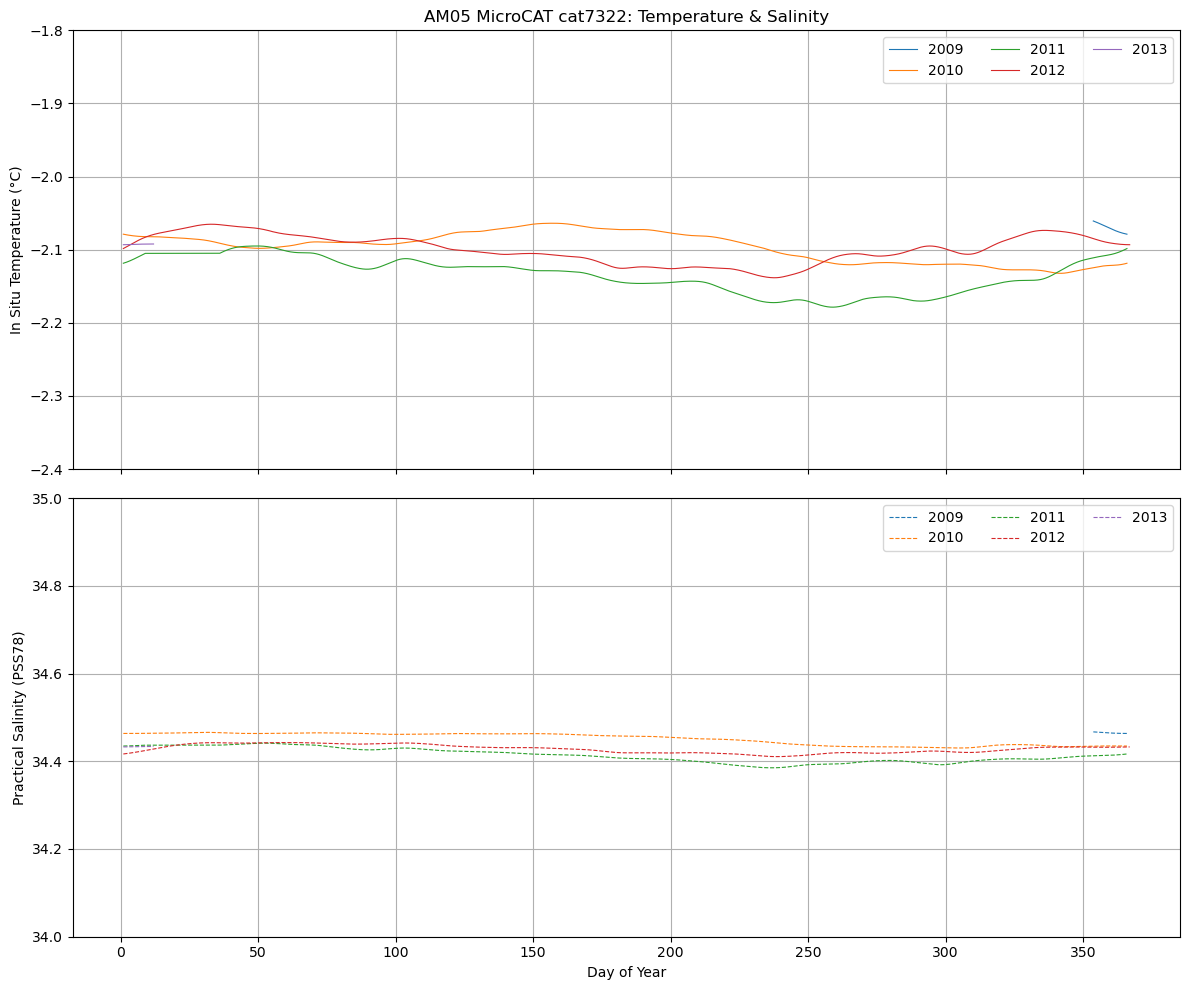

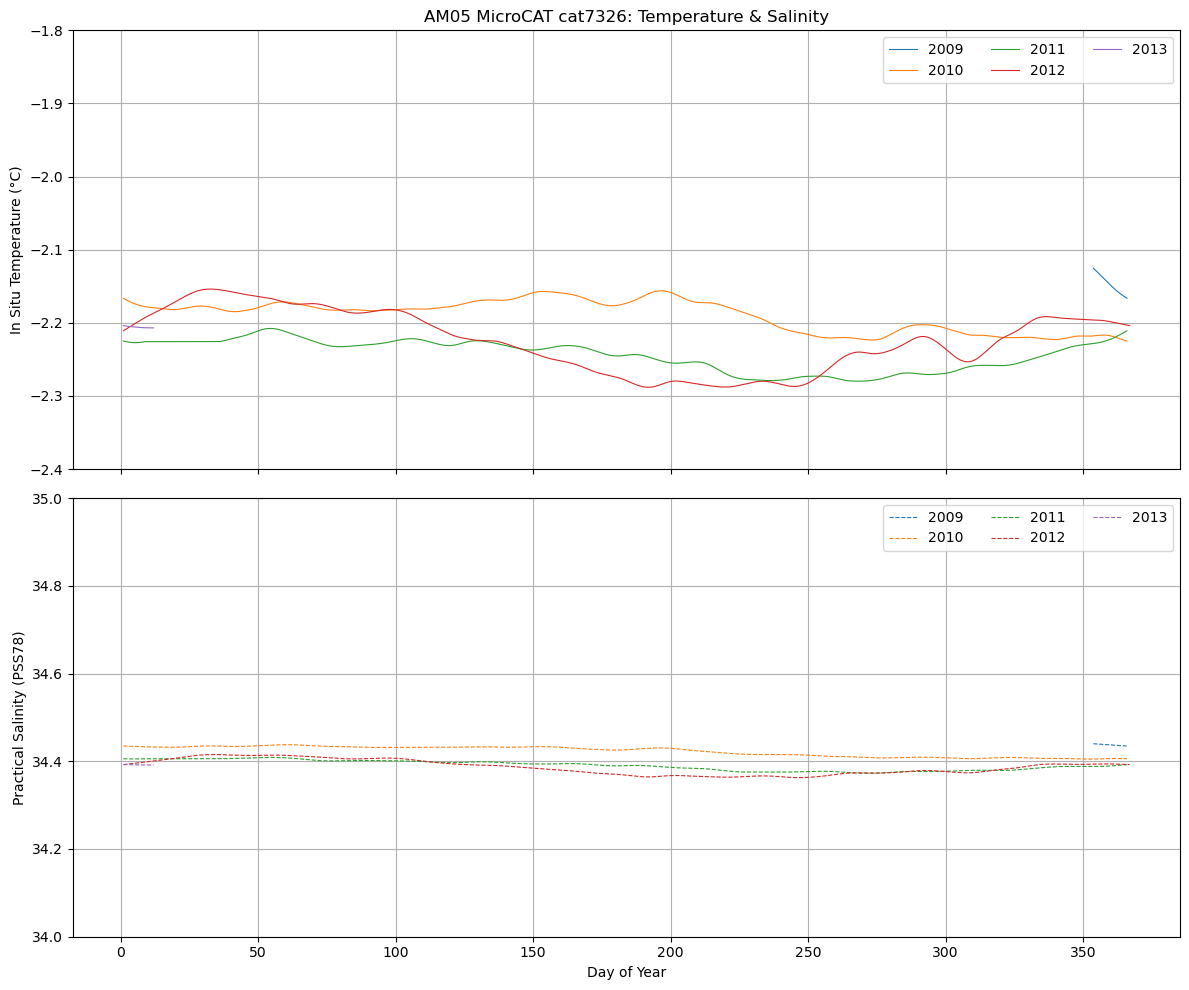

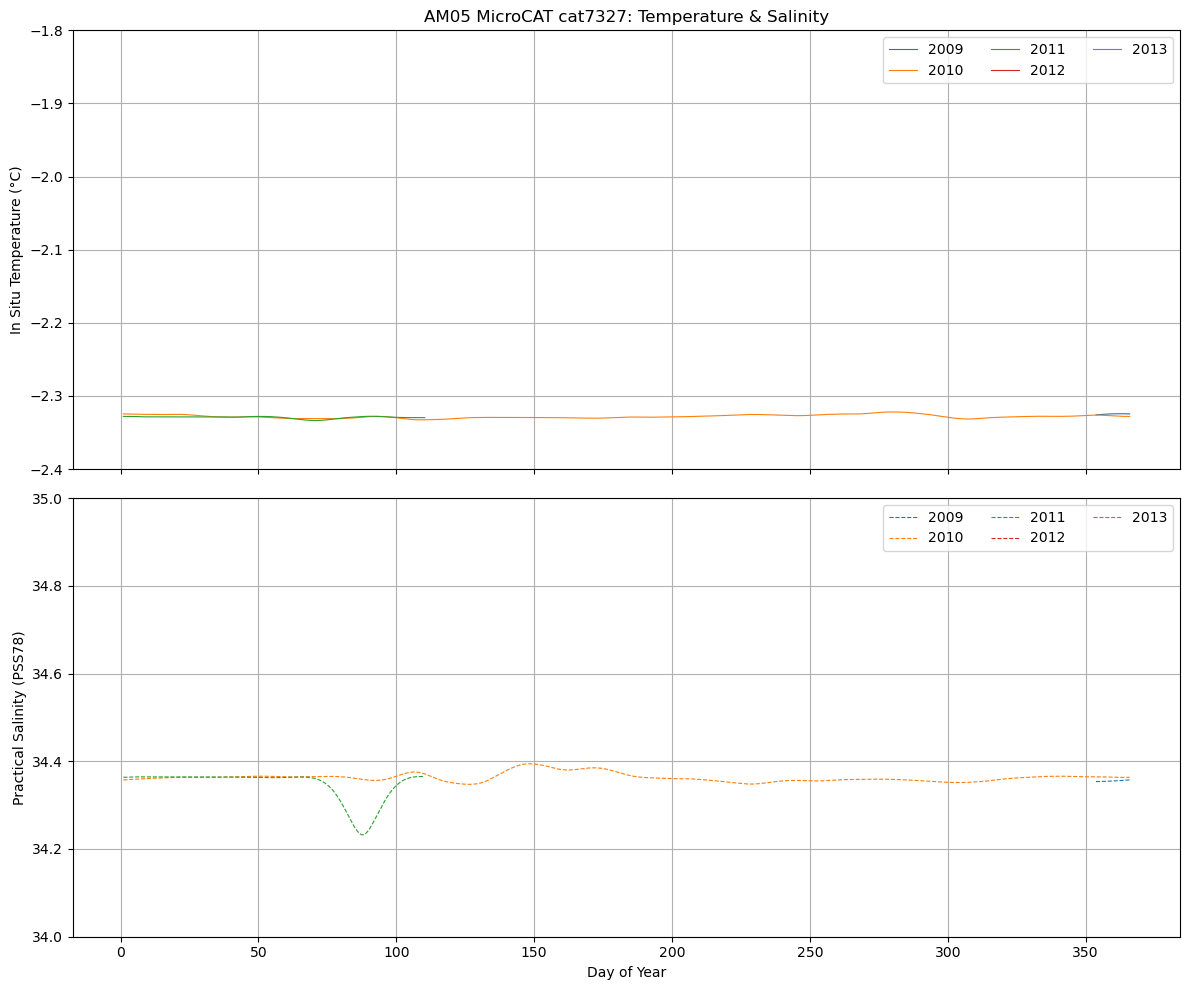

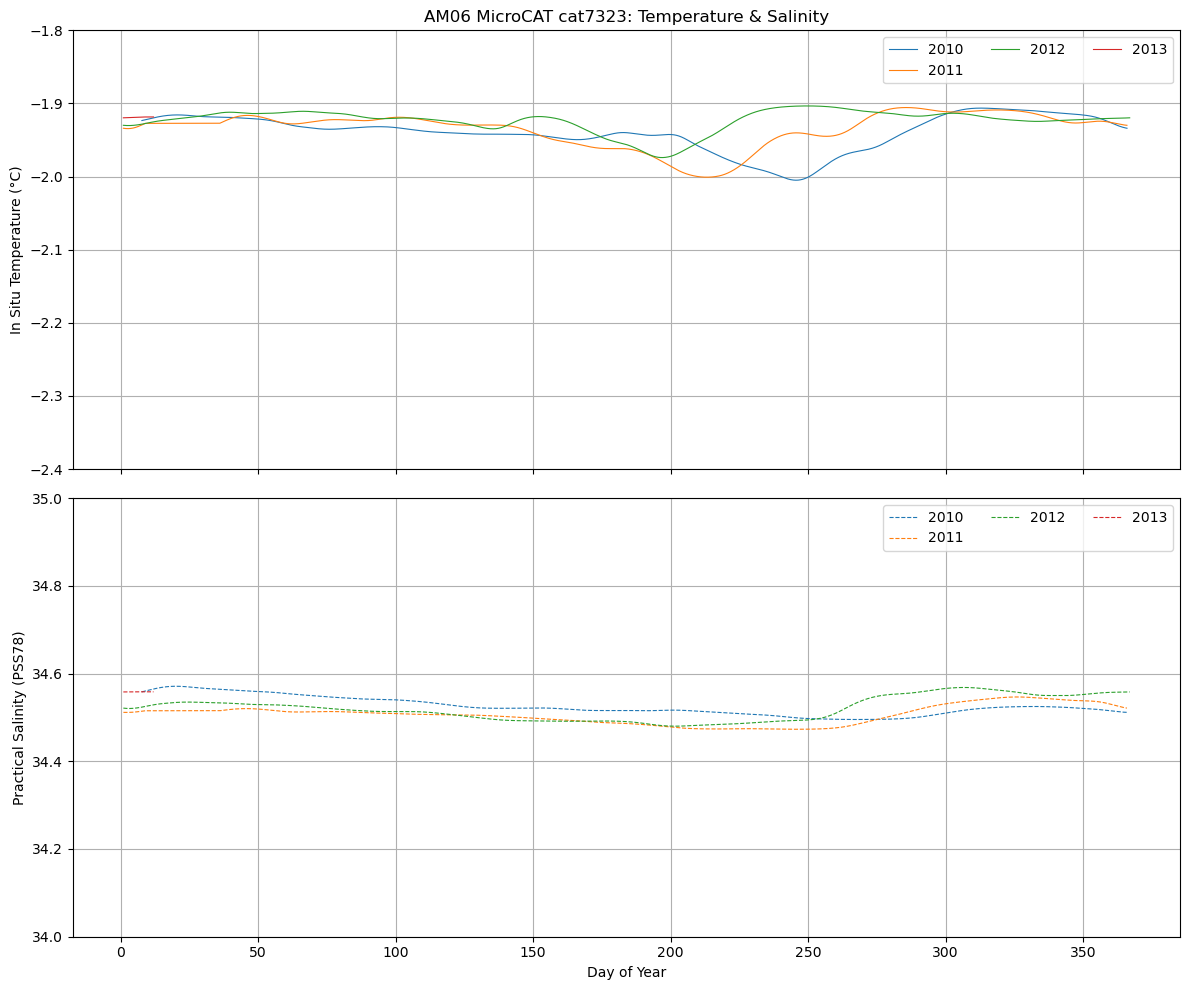

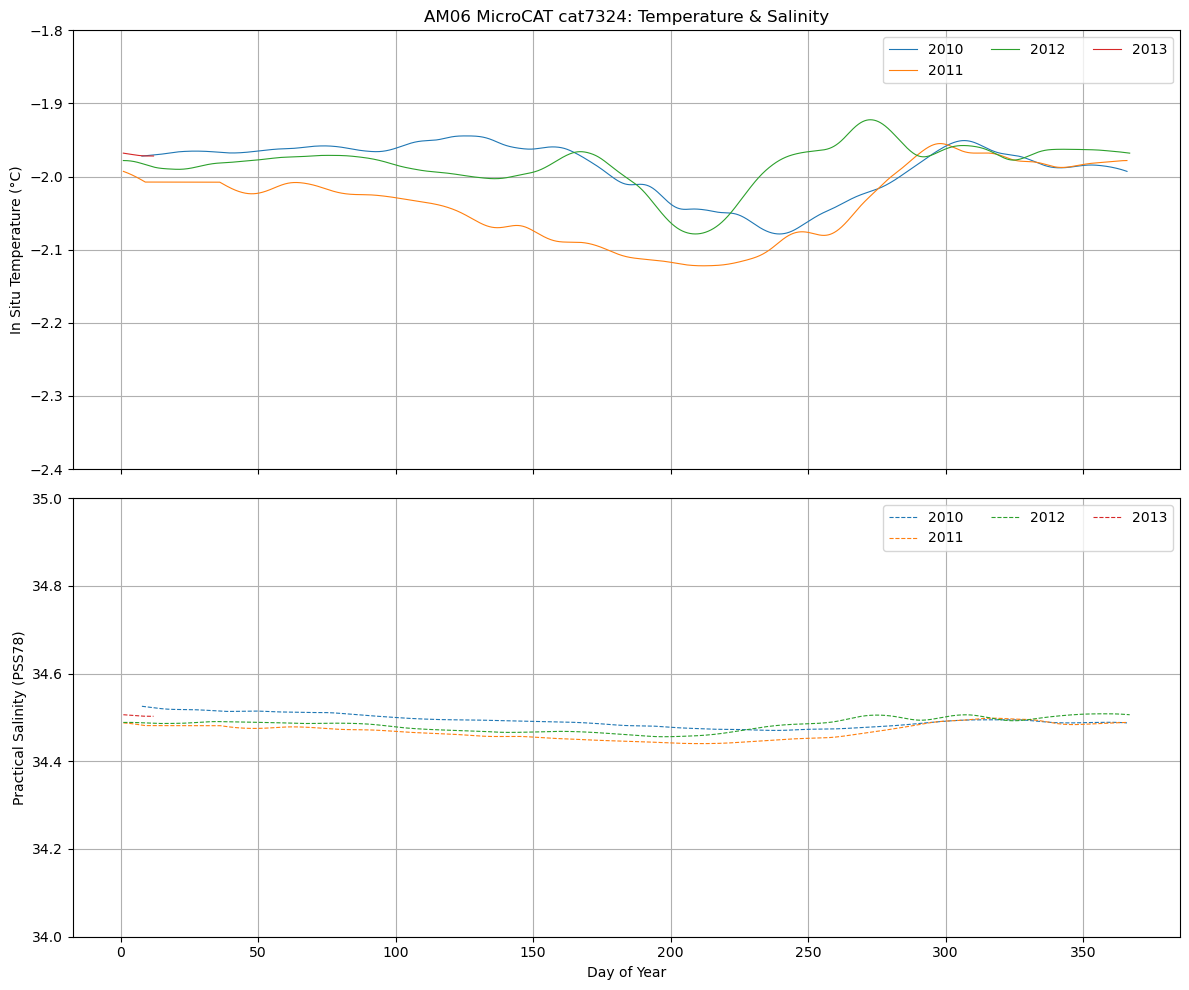

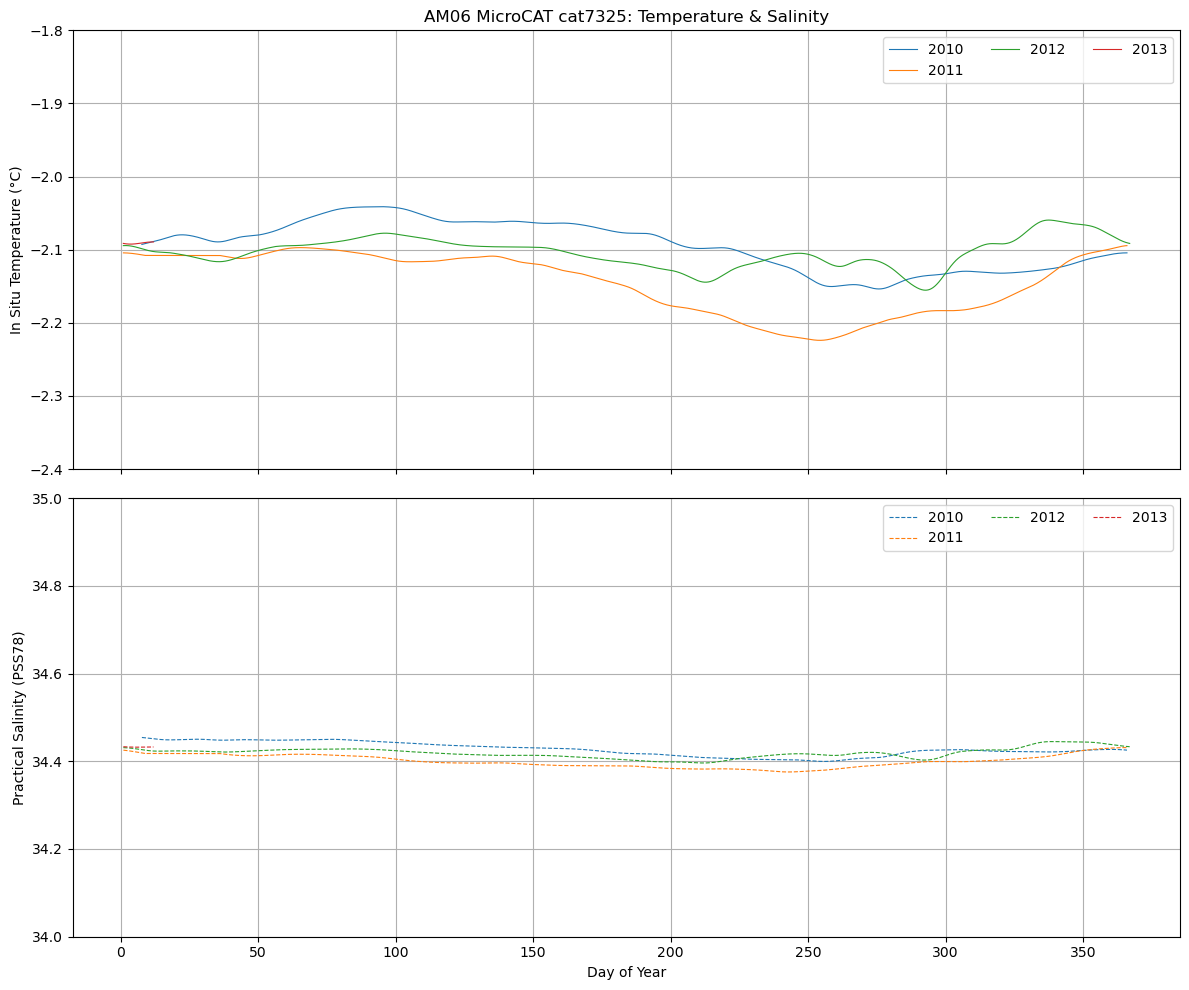

In [17]:
boreholes = sorted(df_filtered["borehole"].unique())
for borehole in boreholes:
    borehole_data = df_filtered[df_filtered["borehole"] == borehole]
    cats = sorted(borehole_data["cat"].unique())
    for cat in cats:
         plot_doy(df_filtered, borehole, cat, (-2.4, -1.8), (34, 35))